# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'nraja3'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

In [25]:
print(d.head())
print("Number of supernovae:", len(d))

          z        m_B  sigma_m
0  0.055108  17.790878      0.1
1  0.062246  17.894206      0.1
2  0.068856  18.075162      0.1
3  0.080527  18.290859      0.1
4  0.089199  18.910605      0.1
Number of supernovae: 500


## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

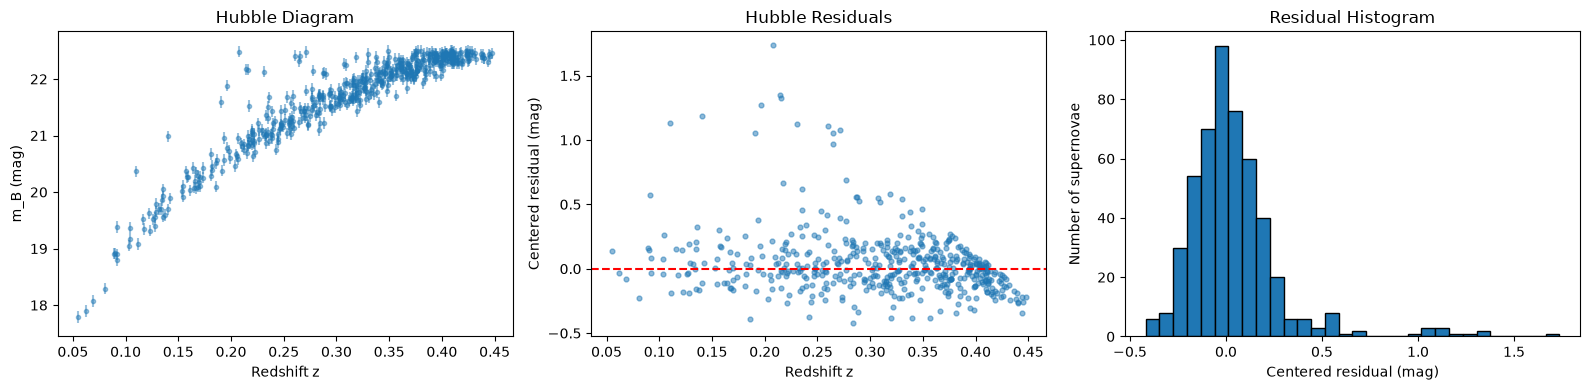

Residual standard deviation: 0.2540123478266723 mag


In [46]:
# Part 1: your work here

from astropy.cosmology import FlatLambdaCDM

Om_guess = 0.3
cosmo = FlatLambdaCDM(H0=70, Om0=Om_guess)

mu_ref = cosmo.distmod(z).value

raw_residual = m - mu_ref
residual = raw_residual - np.median(raw_residual)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].errorbar(z, m, yerr=sig_m,
               fmt='.', alpha=0.45)
ax[0].set_xlabel('Redshift z')
ax[0].set_ylabel('m_B (mag)')
ax[0].set_title('Hubble Diagram')

ax[1].scatter(z, residual, s=12, alpha=0.5)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel('Redshift z')
ax[1].set_ylabel('Centered residual (mag)')
ax[1].set_title('Hubble Residuals')

ax[2].hist(residual, bins=30, edgecolor='black')
ax[2].set_xlabel('Centered residual (mag)')
ax[2].set_ylabel('Number of supernovae')
ax[2].set_title('Residual Histogram')

plt.tight_layout()
plt.show()

print("Residual standard deviation:",
      np.std(residual), "mag")




In [51]:
from scipy.integrate import cumulative_trapezoid
from astropy.cosmology import FlatLambdaCDM

H0 = 70.0
c = 299792.458  # km/s

om_grid = np.arange(0.005, 1.001, 0.005)
z_grid = np.linspace(0, 0.7, 701)

E = np.sqrt(
    om_grid[:, None] * (1 + z_grid[None, :])**3
    + (1 - om_grid[:, None])
)

integral = cumulative_trapezoid(
    1 / E, z_grid, axis=1, initial=0
)

DL = (c / H0) * (1 + z_grid[None, :]) * integral
mu_table = np.full_like(DL, np.nan)
mu_table[:, 1:] = 5 * np.log10(DL[:, 1:]) + 25

def fast_mu(z, Om):
    z = np.asarray(z)
    i = np.searchsorted(om_grid, Om)
    i = np.clip(i, 1, len(om_grid) - 1)

    om_lo, om_hi = om_grid[i-1], om_grid[i]
    w = (Om - om_lo) / (om_hi - om_lo)

    mu_lo = np.interp(z, z_grid[1:], mu_table[i-1, 1:])
    mu_hi = np.interp(z, z_grid[1:], mu_table[i, 1:])

    return (1-w)*mu_lo + w*mu_hi

# Verify against astropy
test_z = np.array([0.05, 0.2, 0.5])
test_Om = 0.3

exact = FlatLambdaCDM(
    H0=70, Om0=test_Om
).distmod(test_z).value

approx = fast_mu(test_z, test_Om)

print("Maximum interpolation error:",
      np.max(np.abs(exact-approx)), "mag")



Maximum interpolation error: 4.724303437342314e-08 mag


![Image](IMG_1617.JPG)

In [28]:
M_IA_MEAN = -19.30
M_IA_STD = 0.12
M_CC_MEAN = -18.5
M_CC_STD = 0.5

def draw_redshifts(rng, n):
    z_min = 0.01
    z_max = 0.7

    u = rng.random(n)

    return (z_min**3 + u * (z_max**3 - z_min**3))**(1/3)

def simulate(Om, f, rng):
    n = 500

    z_sim = draw_redshifts(rng, n)
    is_cc = rng.random(n) < f

    M = np.where(
        is_cc,
        rng.normal(M_CC_MEAN, M_CC_STD, n),
        rng.normal(M_IA_MEAN, M_IA_STD, n)
    )

    mu = fast_mu(z_sim, Om)
    sigma = np.full(n, 0.10)

    m_sim = M + mu + rng.normal(0, sigma, n)

    return pd.DataFrame({
        'z': z_sim,
        'm_B': m_sim,
        'sigma_m': sigma
    })

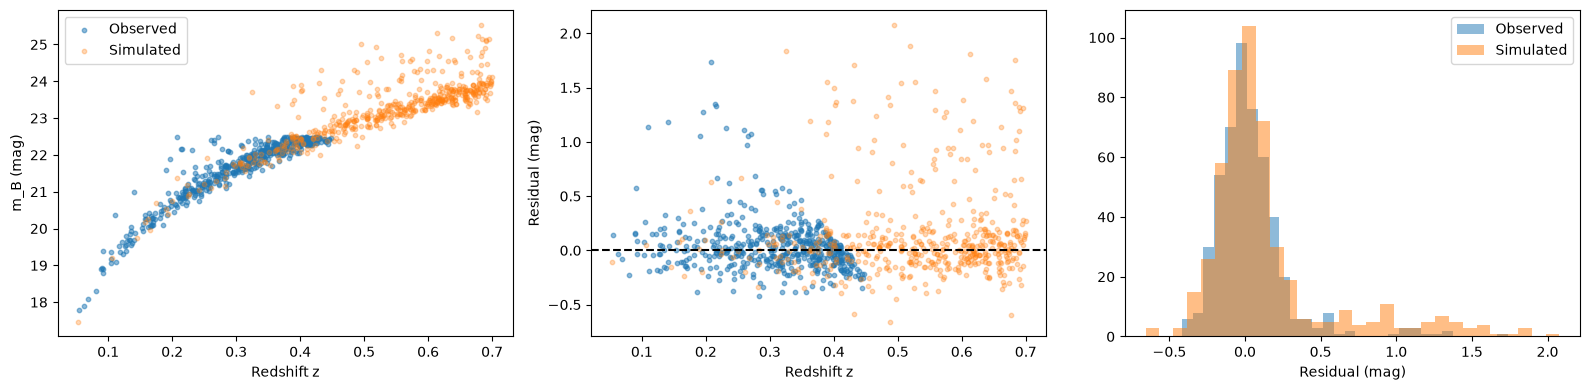

In [29]:
rng = np.random.default_rng(457)

sim = simulate(0.3, 0.2, rng)

zs = sim['z'].to_numpy()
ms = sim['m_B'].to_numpy()

res_obs = m - fast_mu(z, 0.3) - M_IA_MEAN
res_sim = ms - fast_mu(zs, 0.3) - M_IA_MEAN

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(z, m, s=10, alpha=0.5, label='Observed')
ax[0].scatter(zs, ms, s=10, alpha=0.3, label='Simulated')
ax[0].set_xlabel('Redshift z')
ax[0].set_ylabel('m_B (mag)')
ax[0].legend()

ax[1].scatter(z, res_obs, s=10, alpha=0.5)
ax[1].scatter(zs, res_sim, s=10, alpha=0.3)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set_xlabel('Redshift z')
ax[1].set_ylabel('Residual (mag)')

ax[2].hist(res_obs, bins=30, alpha=0.5, label='Observed')
ax[2].hist(res_sim, bins=30, alpha=0.5, label='Simulated')
ax[2].set_xlabel('Residual (mag)')
ax[2].legend()

plt.tight_layout()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

The Hubble diagram shows that supernovae get fainter as redshift increases. Most residuals are near zero, but some are much higher, likely because of core-collapse impostors. The residual spread is about 0.254 mag.

I also noticed the observed redshifts stop around 0.45 instead of 0.7. I would account for this cutoff in my simulations.

My PGM shows Ωₘ and f as parameters, supernova type and absolute magnitude as latent variables, and redshift and apparent magnitude as observed data. Ωₘ affects distance, while f controls the number of impostors.

My simulator creates 500 supernovae with random redshifts, types, magnitudes, and measurement noise. The simulated data look similar, but extend to higher redshifts. I checked the distance calculations against Astropy, and the maximum error was only 4.7 × 10⁻⁸ mag.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [30]:
# Part 2: your work here

from scipy.optimize import minimize_scalar, brentq

# Type Ia absolute magnitude
M_Ia = -19.30

# Total uncertainty: measurement + intrinsic scatter
sigma_total = np.sqrt(sig_m**2 + 0.12**2)

# Chi-square function
def chi2(Om):
    predicted = M_Ia + fast_mu(z, Om)
    return np.sum(((m - predicted) / sigma_total)**2)

# Find best-fit Omega_m
result = minimize_scalar(
    chi2, bounds=(0.005, 1.0),
    method='bounded'
)

Om_best = result.x
chi2_min = result.fun

# 1-sigma error from Delta chi-square = 1
target = chi2_min + 1

Om_low = brentq(
    lambda Om: chi2(Om) - target,
    0.005, Om_best
)

Om_high = brentq(
    lambda Om: chi2(Om) - target,
    Om_best, 1.0
)

Om_err = (Om_high - Om_low) / 2

print(f"Omega_m = {Om_best:.4f} +/- {Om_err:.4f}")
print(f"68% interval: [{Om_low:.4f}, {Om_high:.4f}]")
print(f"Minimum chi-square = {chi2_min:.2f}")

Omega_m = 0.2540 +/- 0.0134
68% interval: [0.2406, 0.2674]
Minimum chi-square = 1345.56


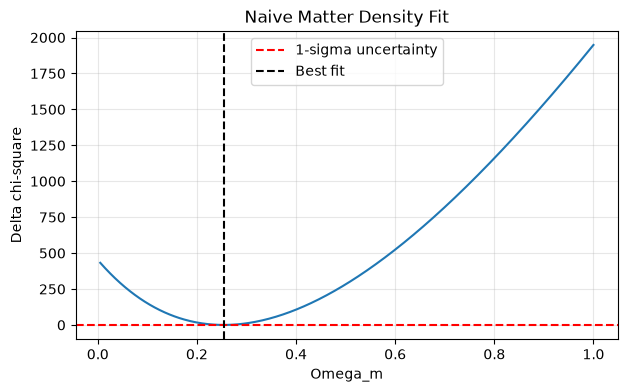

In [31]:
Om_values = np.linspace(0.005, 1.0, 500)
chi2_values = np.array([chi2(Om) for Om in Om_values])

plt.figure(figsize=(7, 4))

plt.plot(Om_values, chi2_values - chi2_min)
plt.axhline(1, color='red', linestyle='--',
            label='1-sigma uncertainty')
plt.axvline(Om_best, color='black', linestyle='--',
            label='Best fit')

plt.xlabel('Omega_m')
plt.ylabel('Delta chi-square')
plt.title('Naive Matter Density Fit')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

Assuming all supernovae are Type Ia, I got Ωₘ = 0.2540 ± 0.0134 (1σ) by minimizing chi-square.

The impostors are fainter than Type Ia supernovae, so they appear higher on the Hubble diagram. This makes them seem farther away and pushes the fitted Ωₘ lower than its true value.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

In [36]:
# Part 3: your work here

# Reference cosmology
OM_REF = 0.3

# Observed redshift cutoff (diagnostic)
print("Observed z range:", z.min(), z.max())

# Use the actual observed redshifts in ABC simulations.
# This conditions on the observed redshift selection.
z_abc = z.copy()

mu_reference = fast_mu(z_abc, OM_REF)

def summaries(magnitudes):
    r = magnitudes - M_IA_MEAN - mu_reference

    zmid = np.median(z_abc)
    low = z_abc <= zmid
    high = z_abc > zmid

    return np.array([
        np.median(r),
        np.median(r[high]) - np.median(r[low]),
        np.mean(r > 0.5)
    ])

S_obs = summaries(m)

names = [
    "Median residual (mag)",
    "High - low redshift residual (mag)",
    "Fraction with residual > 0.5 mag"
]

for name, value in zip(names, S_obs):
    print(f"{name}: {value:.4f}")


Observed z range: 0.055108 0.447493
Median residual (mag): -0.0003
High - low redshift residual (mag): -0.0460
Fraction with residual > 0.5 mag: 0.0460


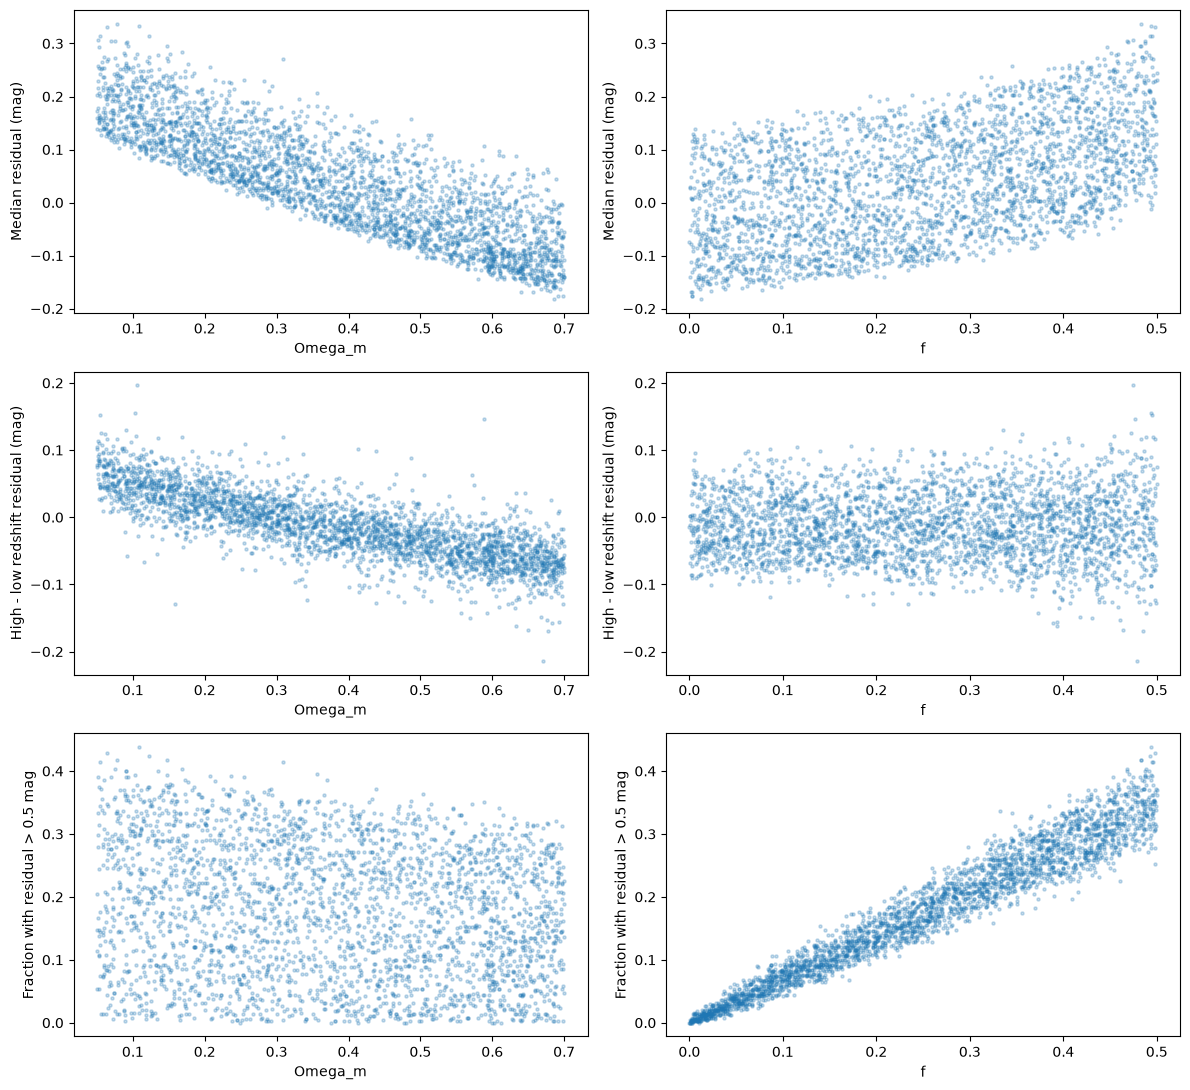

In [37]:
OM_MIN = 0.05
OM_MAX = 0.70

F_MIN = 0.0
F_MAX = 0.50

assert all(v is not None for v in
           [OM_MIN, OM_MAX, F_MIN, F_MAX]), \
    "Fill in the four prior bounds first."

rng = np.random.default_rng(457)

def simulate_abc(Om, f, rng):
    """Simulate magnitudes conditional on observed redshifts."""
    n = len(z_abc)

    is_cc = rng.random(n) < f

    M = np.where(
        is_cc,
        rng.normal(-18.5, 0.5, n),
        rng.normal(-19.30, 0.12, n)
    )

    noise = rng.normal(0, sig_m, n)

    return M + fast_mu(z_abc, Om) + noise

# First 3,000 simulations for summary diagnostics
N_check = 3000

theta_check = np.column_stack([
    rng.uniform(OM_MIN, OM_MAX, N_check),
    rng.uniform(F_MIN, F_MAX, N_check)
])

S_check = np.array([
    summaries(simulate_abc(Om, f, rng))
    for Om, f in theta_check
])

fig, ax = plt.subplots(3, 2, figsize=(12, 11))

for j in range(3):
    ax[j, 0].scatter(theta_check[:, 0], S_check[:, j],
                     s=5, alpha=0.25)
    ax[j, 0].set_xlabel("Omega_m")
    ax[j, 0].set_ylabel(names[j])

    ax[j, 1].scatter(theta_check[:, 1], S_check[:, j],
                     s=5, alpha=0.25)
    ax[j, 1].set_xlabel("f")
    ax[j, 1].set_ylabel(names[j])

plt.tight_layout()
plt.show()

In [38]:
N_ABC = 50000

rng = np.random.default_rng(458)

theta = np.column_stack([
    rng.uniform(OM_MIN, OM_MAX, N_ABC),
    rng.uniform(F_MIN, F_MAX, N_ABC)
])

S_sim = np.empty((N_ABC, 3))

for i, (Om, f) in enumerate(theta):
    m_fake = simulate_abc(Om, f, rng)
    S_sim[i] = summaries(m_fake)

# Save results so we do not need to simulate again
np.savez(
    "lab09_abc_simulations.npz",
    theta=theta,
    S_sim=S_sim,
    S_obs=S_obs
)

print("Completed", N_ABC, "simulations")


Completed 50000 simulations


Loose epsilon: 0.9314837440003796
Tight epsilon: 0.5895690358038325
Accepted (loose): 5000
Accepted (tight): 1000


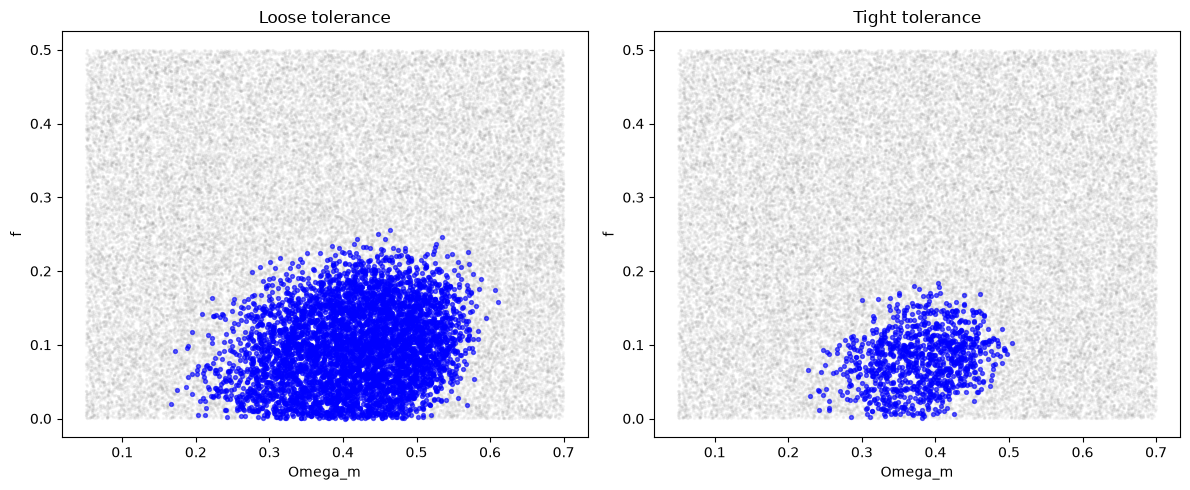

In [40]:

# Standardize differences
scale = np.std(S_sim, axis=0, ddof=1)
scale = np.maximum(scale, 1e-10)

distance = np.sqrt(
    np.sum(((S_sim - S_obs) / scale)**2, axis=1)
)

eps_loose = np.quantile(distance, 0.10)
eps_tight = np.quantile(distance, 0.02)

keep_loose = distance <= eps_loose
keep_tight = distance <= eps_tight

print("Loose epsilon:", eps_loose)
print("Tight epsilon:", eps_tight)
print("Accepted (loose):", keep_loose.sum())
print("Accepted (tight):", keep_tight.sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for a, keep, title in zip(
    ax,
    [keep_loose, keep_tight],
    ["Loose tolerance", "Tight tolerance"]
):
    a.scatter(theta[:, 0], theta[:, 1],
              s=2, alpha=0.05, color="gray")
    a.scatter(theta[keep, 0], theta[keep, 1],
              s=8, alpha=0.6, color="blue")

    a.set_xlabel("Omega_m")
    a.set_ylabel("f")
    a.set_title(title)

plt.tight_layout()
plt.show()

FINAL ABC RESULTS
Omega_m = 0.3827
95% interval: [0.2770, 0.4716]
f = 0.0811
95% interval: [0.0105, 0.1545]

Part 2 naive Omega_m = 0.2540 +/- 0.0134
Difference from naive fit: 0.12869408772172242


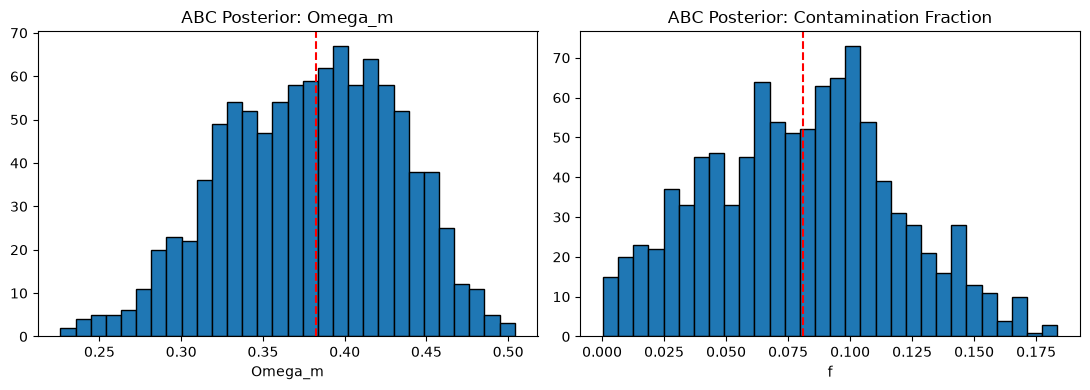

In [41]:

posterior = theta[keep_tight]

Om_post = posterior[:, 0]
f_post = posterior[:, 1]

Om_med = np.median(Om_post)
Om_low, Om_high = np.percentile(Om_post, [2.5, 97.5])

f_med = np.median(f_post)
f_low, f_high = np.percentile(f_post, [2.5, 97.5])

print("FINAL ABC RESULTS")
print(f"Omega_m = {Om_med:.4f}")
print(f"95% interval: [{Om_low:.4f}, {Om_high:.4f}]")

print(f"f = {f_med:.4f}")
print(f"95% interval: [{f_low:.4f}, {f_high:.4f}]")

print("\nPart 2 naive Omega_m = 0.2540 +/- 0.0134")
print("Difference from naive fit:", Om_med - 0.2540)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(Om_post, bins=30, edgecolor="black")
ax[0].axvline(Om_med, color="red", linestyle="--")
ax[0].set_xlabel("Omega_m")
ax[0].set_title("ABC Posterior: Omega_m")

ax[1].hist(f_post, bins=30, edgecolor="black")
ax[1].axvline(f_med, color="red", linestyle="--")
ax[1].set_xlabel("f")
ax[1].set_title("ABC Posterior: Contamination Fraction")

plt.tight_layout()
plt.show()

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

I used three summaries: median residual, the difference between high and low redshift residuals, and the fraction above 0.5 mag. The first two help estimate Ωₘ, while the last tracks f.

I ran 50,000 simulations using standardized distances. I tested ε = 0.9315 (5,000 kept) and ε = 0.5896 (1,000 kept). I chose the smaller ε because it gives a closer match.

My final results were:

Ωₘ = 0.3827, 95% interval: [0.2770, 0.4716]

f = 0.0811, 95% interval: [0.0105, 0.1545]

Part 2 gave Ωₘ = 0.2540 ± 0.0134. ABC gives a higher value because it accounts for the fainter impostors that pushed the first fit too low.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

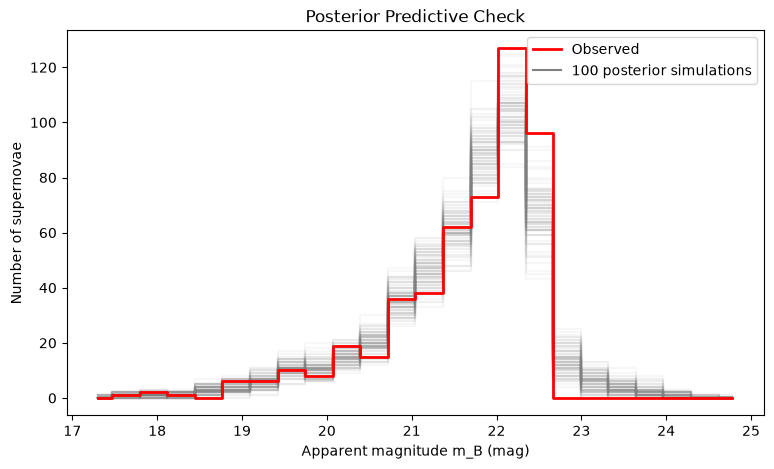

Observed magnitude std: 0.8708
Simulated median std: 0.9285
Simulated 95% range: [0.899  0.9629]
Observed within simulated range: False


In [42]:
# Part 4: your work here

rng_ppc = np.random.default_rng(459)

posterior = theta[keep_tight]

indices = rng_ppc.choice(
    len(posterior), size=100, replace=False
)

m_ppc = np.array([
    simulate_abc(*posterior[i], rng_ppc)
    for i in indices
])

# Compare apparent magnitude histograms
bins = np.linspace(
    min(m.min(), m_ppc.min()),
    max(m.max(), m_ppc.max()),
    25
)

obs_counts, _ = np.histogram(m, bins=bins)

sim_counts = np.array([
    np.histogram(fake, bins=bins)[0]
    for fake in m_ppc
])

centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(9, 5))

for counts in sim_counts:
    plt.step(
        centers, counts,
        where='mid',
        color='gray',
        alpha=0.06
    )

plt.step(
    centers, obs_counts,
    where='mid',
    color='red',
    linewidth=2,
    label='Observed'
)

plt.plot([], [], color='gray',
         label='100 posterior simulations')

plt.xlabel('Apparent magnitude m_B (mag)')
plt.ylabel('Number of supernovae')
plt.title('Posterior Predictive Check')
plt.legend()
plt.show()

# Numerical comparison
obs_std = np.std(m, ddof=1)
sim_std = np.std(m_ppc, axis=1, ddof=1)

print("Observed magnitude std:", round(obs_std, 4))
print("Simulated median std:", round(np.median(sim_std), 4))
print("Simulated 95% range:",
      np.round(np.percentile(sim_std, [2.5, 97.5]), 4))
print("Observed within simulated range:",
      np.percentile(sim_std, 2.5) <= obs_std <=
      np.percentile(sim_std, 97.5))

In [43]:
rng_cov = np.random.default_rng(460)

N_tests = 20

test_indices = rng_cov.choice(
    len(theta), size=N_tests, replace=False
)

covered_Om = []
covered_f = []

for j, idx in enumerate(test_indices):

    true_Om, true_f = theta[idx]
    fake_observed = S_sim[idx]

    # Exclude the test simulation itself
    valid = np.ones(len(theta), dtype=bool)
    valid[idx] = False

    theta_other = theta[valid]
    S_other = S_sim[valid]

    # Standardized ABC distance
    scale = np.std(S_other, axis=0, ddof=1)

    dist = np.sqrt(np.sum(
        ((S_other - fake_observed) / scale)**2,
        axis=1
    ))

    # Same 2% acceptance rule as Part 3
    eps = np.quantile(dist, 0.02)
    accepted = theta_other[dist <= eps]

    # 95% intervals
    Om_ci = np.percentile(accepted[:, 0], [2.5, 97.5])
    f_ci = np.percentile(accepted[:, 1], [2.5, 97.5])

    covered_Om.append(
        Om_ci[0] <= true_Om <= Om_ci[1]
    )
    covered_f.append(
        f_ci[0] <= true_f <= f_ci[1]
    )

    print(
        f"Test {j+1}: "
        f"Omega_m covered = {covered_Om[-1]}, "
        f"f covered = {covered_f[-1]}"
    )

print("\nFINAL COVERAGE RESULTS")
print(f"Omega_m coverage: {np.mean(covered_Om)*100:.1f}%")
print(f"f coverage: {np.mean(covered_f)*100:.1f}%")
print(f"Expected coverage: 95%")

Test 1: Omega_m covered = True, f covered = True
Test 2: Omega_m covered = True, f covered = True
Test 3: Omega_m covered = True, f covered = True
Test 4: Omega_m covered = True, f covered = True
Test 5: Omega_m covered = True, f covered = True
Test 6: Omega_m covered = True, f covered = True
Test 7: Omega_m covered = True, f covered = True
Test 8: Omega_m covered = True, f covered = True
Test 9: Omega_m covered = True, f covered = True
Test 10: Omega_m covered = True, f covered = True
Test 11: Omega_m covered = True, f covered = True
Test 12: Omega_m covered = True, f covered = True
Test 13: Omega_m covered = True, f covered = True
Test 14: Omega_m covered = True, f covered = True
Test 15: Omega_m covered = True, f covered = True
Test 16: Omega_m covered = True, f covered = True
Test 17: Omega_m covered = True, f covered = True
Test 18: Omega_m covered = True, f covered = True
Test 19: Omega_m covered = True, f covered = True
Test 20: Omega_m covered = True, f covered = True

FINAL CO

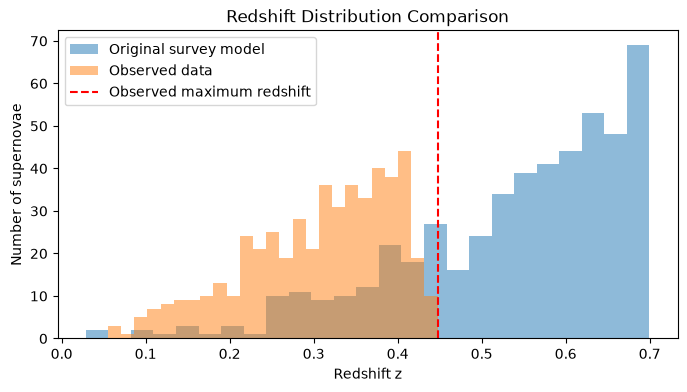

Maximum observed redshift: 0.4475
Maximum simulated redshift: 0.6997


In [44]:
rng_check = np.random.default_rng(461)

z_full = draw_redshifts(rng_check, 500)

plt.figure(figsize=(8, 4))

plt.hist(z_full, bins=25, alpha=0.5,
         label='Original survey model')
plt.hist(z, bins=25, alpha=0.5,
         label='Observed data')

plt.axvline(z.max(), color='red',
            linestyle='--',
            label='Observed maximum redshift')

plt.xlabel('Redshift z')
plt.ylabel('Number of supernovae')
plt.title('Redshift Distribution Comparison')
plt.legend()
plt.show()

print(f"Maximum observed redshift: {z.max():.4f}")
print(f"Maximum simulated redshift: {z_full.max():.4f}")


**ANSWER (the check, the coverage, and the assumption):**

The 100 simulations were similar to the real data, but not perfect. The observed spread was 0.8708 mag, while the simulated spread was 0.9285 mag, outside the 95% range of [0.8990, 0.9629] mag.

Both Ωₘ and f had 100% coverage (20/20 tests), close to the expected 95%.

My simulator assumes faint supernovae aren't missed. Real surveys can miss them, making Ωₘ too high. The observed redshifts also stop at 0.4475 instead of 0.7, showing the model isn't completely accurate.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used ChatGPT to help write Python code, create plots, and explain my results. It initially gave me an incomplete simulator and used the wrong redshift distribution. I caught these mistakes by comparing the code with the lab instructions and fixing the errors.

**REFLECTION:**

Without checking the AI's code, I would have used the wrong redshift distribution and gotten inaccurate results for Ωₘ and f. This could have made my final estimates biased.

**VERIFICATION PLAN:**

I checked my distance calculations against Astropy and found a maximum error of 4.7 × 10⁻⁸ mag. I also compared 100 simulated datasets with my real data and found that the observed spread was outside the simulated 95% range.

For coverage, I tested 20 simulated datasets. Both Ωₘ and f had 100% coverage, close to the expected 95%. Poor coverage would mean my uncertainty intervals were unreliable.

I also compared the redshift distributions and found that the observed data stopped at 0.45 instead of 0.7, showing that my simulator did not fully match the survey.